# `panorama.obs` — Demo

Worked examples of the **`obs`** module of PANORAMA: coordinates, time stamps and barycentric corrections, signal-to-noise ratios, FITS catalogs, visibility, periodic objects and observations.

* **Examples 1-2** — coordinates: every accepted coordinate format, Galactic coordinates, and angular separations and position angles (also between positions given in different frames).
* **Examples 3-4** — time stamps and signal-to-noise ratios: barycentric correction of three spectra of ρ Leo (one or several exposure times, with and without measured velocities), and exposure-time and SNR scaling.
* **Example 5** — a catalog of mock HERMES FITS files (headers only, in `data_and_results/obs/data/observation_fits/`) with their barycentric corrections, including an early-morning exposure assigned to the previous night, an airmass computed from the telescope altitude, a header without `DATE-OBS`, an unreadable file and a calibration file ignored by the pattern.
* **Examples 6-8** — visibility: the ephemerides of a night at the ORM and at a high-latitude site without astronomical night, the visibility of three OB stars over that night (and of a single target given as a coordinate dictionary), and the visibility of ρ Leo over a year.
* **Examples 9-11** — periodic objects (short-period eclipsing binary ASAS J052919-1617.3): upcoming primary and secondary eclipses, phases at given times with HJD and JD reference epochs, and the phase coverage of an observing run (including a night with full coverage and a night without astronomical night).
* **Examples 12-13** — observations: a telescope pointing and the BinarAlt interface (input check only, unless `RUN_BINARALT` is set to `True`). The file `data_and_results/obs/data/northcircumpolar_targets.csv` is an example target list for the *Import CSV* button of BinarAlt.

**Figures** are shown inline and also saved with `savefig_pkl` (PDF + pickle) in `data_and_results/obs/results/`; input files (the mock HERMES FITS files of example 5 and the BinarAlt target list) are read from `data_and_results/obs/data/` (relative to `Demos/`, the folder of this notebook).

**Internet:** not needed. Only the live weather panel of BinarAlt uses it, and BinarAlt is launched only if `RUN_BINARALT = True` (it opens a tab in the default web browser). Run the cells in order (*Run All*).

## Imports

Python packages (figures shown inline) and PANORAMA functions.

In [1]:
%matplotlib inline
from astropy.coordinates import SkyCoord
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import warnings

from panorama import (
                      annual_visibility,  # VISIBILITY
                      bary_corr,  # TIME
                      binaralt,  # OBSERVATIONS
                      combine_SNR,  # SIGNAL-TO-NOISE
                      coord_info,  # COORDINATES
                      estimate_exposure,  # SIGNAL-TO-NOISE
                      estimate_SNR,  # SIGNAL-TO-NOISE
                      fits_catalog,  # DATA
                      night_info,  # VISIBILITY
                      obs_phase,  # PERIODIC OBJECTS
                      obs_phase_night,  # PERIODIC OBJECTS
                      periodic_event,  # PERIODIC OBJECTS
                      savefig_pkl,  # MATPLOTLIB (tex module)
                      sky_dist,  # COORDINATES
                      telescope_pointing,  # OBSERVATIONS
                      visibility,  # VISIBILITY
                     )

	PANORAMA v1.2.1 loaded...
		- To see the available functions, run:
			panorama.functions()          # Lists all functions, grouped by submodule
			panorama.functions('obs')     # Lists the functions of a single submodule
		- To see the docstring of a specific function (e.g. 'visibility'), run:
			help(panorama.visibility)
		- To silence this message, set the environment variable PANORAMA_QUIET=1



## Setup

Working directories, observatory, demo targets and mock HERMES FITS files.

In [2]:
work_dir_data    = Path("./data_and_results/obs/data/")
work_dir_results = Path("./data_and_results/obs/results/")
work_dir_results.mkdir(parents=True, exist_ok=True)

RUN_BINARALT = False  # Set to True to launch the BinarAlt interface in example 13 (opens a browser tab; the server stops with the kernel)

observatory = "ORM"  # Observatorio del Roque de los Muchachos (La Palma)
night       = "2026-11-01"  # Night starting on 1 November 2026

targets = {
           'rho Leo'   : "10:32:48.67 +09:18:23.7",  # HD 91316, B1 Iab
           'zeta Oph'  : "16:37:09.54 -10:34:01.5",  # HD 149757, O9.2 IVnn
           'Trapezium' : "05:35:16.46 -05:23:22.8",  # theta1 Ori C, O7 Vp
          }

# Custom observatory without astronomical night around the June solstice (examples 6 and 11)
high_latitude_site = {
                      'name'      : "High-latitude site (60 N)",
                      'longitude' : 10.0,  # deg, East positive
                      'latitude'  : 60.0,  # deg, North positive
                      'elevation' : 100.0,  # m above sea level
                      'timezone'  : "Europe/Oslo",
                     }

# ASAS J052919-1617.3 short-period eclipsing binary used in examples 9-11 (coordinates and ephemeris for demonstration only)
binary_coords = "05:29:19.32 -16:17:18.7"
binary_period = 0.66085103  # Days
binary_hjd0   = 2459929.50048  # Reference epoch of the primary minimum (HJD, UTC)


# Mock HERMES FITS files (headers only, distributed with the repository) read by 'fits_catalog' in example 5
fits_dir = work_dir_data / "observation_fits"

## Example 1: Accepted coordinate formats and Galactic coordinates

In [3]:
# Each entry is (format, input as written in the code, value); every format gives RA = 83.82208 deg, Dec = -5.39111 deg
coord_examples = [
                  ("String (colons)",          '"05:35:17.3 -05:23:28"',                                                "05:35:17.3 -05:23:28"),
                  ("String (h/d/m/s)",         '"05h35m17.3s -05d23m28s"',                                              "05h35m17.3s -05d23m28s"),
                  ("String (spaces, SIMBAD)",  '"05 35 17.3 -05 23 28"',                                                "05 35 17.3 -05 23 28"),
                  ("String (decimal degrees)", '"83.82208 -5.39111"',                                                   "83.82208 -5.39111"),
                  ("Tuple (colons)",           '("05:35:17.3", "-05:23:28")',                                           ("05:35:17.3", "-05:23:28")),
                  ("Tuple (h/d/m/s)",          '("05h35m17.3s", "-05d23m28s")',                                         ("05h35m17.3s", "-05d23m28s")),
                  ("Tuple (spaces)",           '("05 35 17.3", "-05 23 28")',                                           ("05 35 17.3", "-05 23 28")),
                  ("Tuple (decimal strings)",  '("83.82208", "-5.39111")',                                              ("83.82208", "-5.39111")),
                  ("Tuple (numbers, degrees)", '(83.82208, -5.39111)',                                                  (83.82208, -5.39111)),
                  ("Tuple (quantities)",       '(5.5881389 * u.hourangle, -5.39111 * u.deg)',                           (5.5881389 * u.hourangle, -5.39111 * u.deg)),
                  ("List (colons)",            '["05:35:17.3", "-05:23:28"]',                                           ["05:35:17.3", "-05:23:28"]),
                  ("List (numbers, degrees)",  '[83.82208, -5.39111]',                                                  [83.82208, -5.39111]),
                  ("Dictionary",               """{'ra': "05:35:17.3", 'dec': "-05:23:28"}""",                          {'ra': "05:35:17.3", 'dec': "-05:23:28"}),
                  ("Dictionary (aliases)",     """{'right_ascension': "05:35:17.3", 'declination': "-05:23:28"}""",     {'right_ascension': "05:35:17.3", 'declination': "-05:23:28"}),
                  ("Dictionary (unit, frame)", """{'ra': 83.82208, 'dec': -5.39111, 'unit': "deg", 'frame': "icrs"}""", {'ra': 83.82208, 'dec': -5.39111, 'unit': "deg", 'frame': "icrs"}),
                  ("SkyCoord",                 'SkyCoord(83.82208 * u.deg, -5.39111 * u.deg, frame="icrs")',            SkyCoord(83.82208 * u.deg, -5.39111 * u.deg, frame="icrs")),
                 ]


width = max(len(written) for _, written, _ in coord_examples)  # Width of the input column

print(f"\n\t{'-' * (2 + 2 + 25 + 1 + width + 2 + 9 + 1 + 10 + 1 + 12 + 1 + 12)}")
print(f"\t{'#':>2}  {'Format':<25} {'Input':<{width}}  {'RA (deg)':>9} {'Dec (deg)':>10} {'RA (hms)':>12} {'Dec (dms)':>12}")
print(f"\t{'-' * (2 + 2 + 25 + 1 + width + 2 + 9 + 1 + 10 + 1 + 12 + 1 + 12)}")
for i, (label, written, coords) in enumerate(coord_examples, start=1):
    info = coord_info(coords)
    print(f"\t{i:2d}  {label:<25} {written:<{width}}  {info['ra']:9.5f} {info['dec']:+10.5f} {info['ra_hms']:>12} {info['dec_dms']:>12}")
print("\t(RA with ':' or 'h' is read in hours; plain numbers and decimal strings in degrees)")

info = coord_info(targets['zeta Oph'])
print(f"\nzeta Oph (runaway O star; ICRS {info['ra_hms']} {info['dec_dms']}):")
print(f"\tl = {info['l']:.2f} deg, b = {info['b']:+.2f} deg (far from the Galactic plane for an O star)")


	-----------------------------------------------------------------------------------------------------------------------------------------------
	 #  Format                    Input                                                               RA (deg)  Dec (deg)     RA (hms)    Dec (dms)
	-----------------------------------------------------------------------------------------------------------------------------------------------
	 1  String (colons)           "05:35:17.3 -05:23:28"                                              83.82208   -5.39111  05:35:17.30  -05:23:28.0
	 2  String (h/d/m/s)          "05h35m17.3s -05d23m28s"                                            83.82208   -5.39111  05:35:17.30  -05:23:28.0
	 3  String (spaces, SIMBAD)   "05 35 17.3 -05 23 28"                                              83.82208   -5.39111  05:35:17.30  -05:23:28.0
	 4  String (decimal degrees)  "83.82208 -5.39111"                                                 83.82208   -5.39111  05:35:17.

## Example 2: Angular separation and position angle

Angular separation and position angle, also between positions in different frames.

In [4]:
coords1     = "10:00:00 +20:00:00"
coords2     = "10:00:10 +20:01:00"
sep         = sky_dist(coords1, coords2)
coords2_gal = SkyCoord(coords2, unit=(u.hourangle, u.deg), frame="icrs").galactic  # Same position, in Galactic coordinates
sep_gal     = sky_dist(coords1, coords2_gal)


print(f"\nCoordinates 1 : {coords1}")
print(f"Coordinates 2 : {coords2}")
print(f"\tSeparation     = {sep['arcsec']:.2f} arcsec ({sep['deg']:.6f} deg)")
print(f"\tPosition angle = {sep['pa']:.2f} deg (East of North)")
print(f"\nCoordinates 2 given in Galactic coordinates (l = {coords2_gal.l.deg:.4f} deg, b = {coords2_gal.b.deg:+.4f} deg):")
print(f"\tSeparation     = {sep_gal['arcsec']:.2f} arcsec, position angle = {sep_gal['pa']:.2f} deg (transformed into the frame of 'coords1')")


Coordinates 1 : 10:00:00 +20:00:00
Coordinates 2 : 10:00:10 +20:01:00
	Separation     = 153.19 arcsec (0.042552 deg)
	Position angle = 66.93 deg (East of North)

Coordinates 2 given in Galactic coordinates (l = 213.7959 deg, b = +50.3061 deg):
	Separation     = 153.19 arcsec, position angle = 66.93 deg (transformed into the frame of 'coords1')


## Example 3: Barycentric correction (rho Leo, ORM)

Barycentric correction of three spectra of rho Leo.

In [5]:
obstimes = ["2026-11-02T04:30:00", "2027-02-15T00:00:00", "2027-05-01T21:30:00"]  # Start of each exposure (UTC)
exptimes = [900, 1200, 600]  # One exposure time per spectrum (s)

# Mock topocentric velocities of a star with a constant barycentric velocity of 42 km/s:
# the measured values change with the Earth's motion and the correction recovers the constant value
rv_true     = 42.0  # km/s
v_bary_mock = bary_corr(targets['rho Leo'], observatory, obstimes, exptime=exptimes)['v_bary']
rv_measured = [float(v) for v in np.round(rv_true - v_bary_mock, 2)]  # Topocentric radial velocities (km/s)

bary = bary_corr(
                 coords=targets['rho Leo'],
                 observatory=observatory,
                 obstime=obstimes,
                 exptime=exptimes,
                 rv=rv_measured
                )

bary_single = bary_corr(
                        coords=targets['rho Leo'],
                        observatory=observatory,
                        obstime=obstimes[0],
                        exptime=900  # A single value is applied to every observation
                       )


print(f"\n\t{'Mid-exposure (UTC)':<24} {'BJD_TDB':>15} {'HJD':>15} {'v_bary':>8} {'RV_obs':>8} {'RV_bary':>8}")
for t, bjd, hjd, vb, rv_obs, rv_b in zip(bary['obstime'], bary['bjd_tdb'], bary['hjd'], bary['v_bary'], rv_measured, bary['rv_bary']):
    print(f"\t{t:<24} {bjd:15.5f} {hjd:15.5f} {vb:8.3f} {rv_obs:8.2f} {rv_b:8.2f}")
print("\n\t(Velocities in km/s; RV_obs changes with the Earth's orbital motion, RV_bary stays at 42 km/s)")
print(f"\nSingle observation without 'rv': v_bary = {bary_single['v_bary'][0]:.3f} km/s, rv_bary = {bary_single['rv_bary']}")


	Mid-exposure (UTC)               BJD_TDB             HJD   v_bary   RV_obs  RV_bary
	2026-11-02 04:37:30.000    2461346.69090   2461346.69011   27.302    14.70    42.00
	2027-02-15 00:10:00.000    2461451.51334   2461451.51255    6.110    35.89    42.00
	2027-05-01 21:35:00.000    2461527.40260   2461527.40181  -26.543    68.54    41.99

	(Velocities in km/s; RV_obs changes with the Earth's orbital motion, RV_bary stays at 42 km/s)

Single observation without 'rv': v_bary = 27.302 km/s, rv_bary = nan


## Example 4: Exposure time and signal-to-noise ratio

In [6]:
snr_init, t_init, snr_target = 100, 600, 300

t_final = estimate_exposure(
                            snr_init=snr_init,
                            t_init=t_init,
                            snr_target=snr_target
                           )
snr_check = estimate_SNR(
                         snr_init=snr_init,
                         t_init=t_init,
                         t_final=t_final
                        )
snr_equal   = combine_SNR([snr_target] * 4)
snr_unequal = combine_SNR([250, 180, 120])


print(f"\nReference exposure: SNR = {snr_init} in {t_init} s (photon-noise regime, SNR ∝ sqrt(t))")
print(f"\n\tExposure time for SNR              = {snr_target}           ---> {t_final:.0f} s ({t_final / 60:.0f} min)")
print(f"\tSNR recovered for t                = {t_final:.0f} s        ---> {snr_check:.1f}")
print(f"\tSNR of 4 co-added spectra with SNR = {snr_target} each      ---> {snr_equal:.0f} (= {snr_target} x sqrt(4))")
print(f"\tSNR of 3 co-added spectra with SNR = 250, 180, 120 ---> {snr_unequal:.0f}")


Reference exposure: SNR = 100 in 600 s (photon-noise regime, SNR ∝ sqrt(t))

	Exposure time for SNR              = 300           ---> 5400 s (90 min)
	SNR recovered for t                = 5400 s        ---> 300.0
	SNR of 4 co-added spectra with SNR = 300 each      ---> 600 (= 300 x sqrt(4))
	SNR of 3 co-added spectra with SNR = 250, 180, 120 ---> 331


## Example 5: FITS catalog with barycentric corrections (HERMES)

Catalog of mock HERMES FITS files with barycentric corrections.

In [7]:
output_catalog = work_dir_results / "fits_catalog_demo.csv"

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    catalog = fits_catalog(
                           folder=fits_dir,
                           instrument="hermes",  # Case-insensitive
                           output_file=output_catalog
                          )


print()
catalog_columns = ['file', 'object', 'night_obs', 'time_obs', 'airmass', 'exptime_s', 'bjd_tdb', 'v_bary_kms']
column_formats  = {
                   'file'       : lambda name: name[:8] + "...",  # Short file names
                   'bjd_tdb'    : "{:.5f}".format,
                   'v_bary_kms' : "{:.3f}".format,
                  }
print(catalog[catalog_columns].to_string(index=False, formatters=column_formats))
print("\n\nNotes on the mock files:")
print("\t- 00981001: taken at 04:30 UTC, before the 09 UTC split hour, so it belongs to the night of 2026-11-01")
print("\t- 00981002: no AIRMASS keyword, airmass computed from TELALT = 62 deg")
print("\t- 00981004: no DATE-OBS, so no observing night and no barycentric correction")
print("\t- 00981005: not a valid FITS file, skipped")
print("\t- 00981006_HRF_TH_ext.fits: calibration file, ignored by the reduced-spectrum pattern")

print("\nWarnings issued by 'fits_catalog':")
for w in caught:
    if w.category is UserWarning:  # Plain warnings of 'fits_catalog' (astropy and astroplan use their own subclasses)
        print(f"\t- {str(w.message).splitlines()[0]}")
print(f"\n\tOutput: {output_catalog}")


       file    object  night_obs time_obs airmass  exptime_s       bjd_tdb v_bary_kms
00981001...  HD 91316 2026-11-01 04:30:00    1.32      900.0 2461346.69090     27.302
00981003...  HD 37022 2026-11-01 23:40:00    1.45      300.0 2461346.49225     18.322
00981002...  HD 91316 2026-11-02 05:10:00  1.1326      900.0 2461347.71877     27.505
00981004... HD 149757        N/A      N/A     N/A      600.0           NaN        NaN


Notes on the mock files:
	- 00981001: taken at 04:30 UTC, before the 09 UTC split hour, so it belongs to the night of 2026-11-01
	- 00981002: no AIRMASS keyword, airmass computed from TELALT = 62 deg
	- 00981004: no DATE-OBS, so no observing night and no barycentric correction
	- 00981005: not a valid FITS file, skipped
	- 00981006_HRF_TH_ext.fits: calibration file, ignored by the reduced-spectrum pattern

Warnings issued by 'fits_catalog':
	- Output catalog 'data_and_results/obs/results/fits_catalog_demo.csv' already exists and will be overwritten.
	- Could no

## Example 6: Observing ephemerides

Sun and Moon ephemerides of an observing night, and a night without astronomical night.

In [8]:
info_night = night_info(observatory, night)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # astroplan warns that the Sun does not reach -12 and -18 deg: expected here
    info_north = night_info(high_latitude_site, "2026-06-21")


night_events = [
                ("Sunset",                      'sunset'),
                ("End of civil twilight",       'civil_evening'),
                ("End of nautical twilight",    'nautical_evening'),
                ("End of astronomical twil.",   'astro_evening'),
                ("Midnight",                    'midnight'),
                ("Start of astronomical twil.", 'astro_morning'),
                ("Start of nautical twilight",  'nautical_morning'),
                ("Start of civil twilight",     'civil_morning'),
                ("Sunrise",                     'sunrise'),
                ("Moonrise",                    'moonrise'),
                ("Moonset",                     'moonset'),
               ]

print()
print(f"{observatory}, night of {night}:")
for label, key in night_events:
    print(f"\t{label:<28} = {info_night[key] if info_night[key] is not None else 'does not happen during the night'}")
print(f"\t{'Night length':<28} = {info_night['night_hours']:.2f} h (sunset to sunrise)")
print(f"\t{'Dark time':<28} = {info_night['dark_hours']:.2f} h (Sun below -18 deg)")
print(f"\t{'LST at midnight':<28} = {info_night['lst_midnight']} (objects with RA ≈ LST transit at midnight)")
print(f"\t{'Moon':<28} = {info_night['moon_illumination']:.0f}% illuminated, {info_night['moon_alt_midnight']:.1f} deg high at midnight")
print(f"\t{'Local time - UTC':<28} = {info_night['utc_offset']:+.0f} h")

print(f"\n{high_latitude_site['name']}, night of 2026-06-21 (no astronomical night):")
print(f"\tAstronomical twilights = {info_north['astro_evening']} / {info_north['astro_morning']}")
print(f"\tNautical twilights     = {info_north['nautical_evening']} / {info_north['nautical_morning']}")
print(f"\tNight length           = {info_north['night_hours']:.2f} h")
print(f"\tDark time              = {info_north['dark_hours']:.2f} h (the Sun never reaches -18 deg)")


ORM, night of 2026-11-01:
	Sunset                       = 2026-11-01 18:26:11
	End of civil twilight        = 2026-11-01 18:50:34
	End of nautical twilight     = 2026-11-01 19:18:32
	End of astronomical twil.    = 2026-11-01 19:46:13
	Midnight                     = 2026-11-02 00:55:07
	Start of astronomical twil.  = 2026-11-02 06:04:19
	Start of nautical twilight   = 2026-11-02 06:32:02
	Start of civil twilight      = 2026-11-02 07:00:02
	Sunrise                      = 2026-11-02 07:24:28
	Moonrise                     = 2026-11-02 00:47:56
	Moonset                      = does not happen during the night
	Night length                 = 12.97 h (sunset to sunrise)
	Dark time                    = 10.30 h (Sun below -18 deg)
	LST at midnight              = 02:28:51 (objects with RA ≈ LST transit at midnight)
	Moon                         = 48% illuminated, 1.4 deg high at midnight
	Local time - UTC             = +0 h

High-latitude site (60 N), night of 2026-06-21 (no astronomical night):

## Example 7: Visibility of several targets over a night

Visibility of several targets over a night, and of a single target given as a coordinate dictionary.

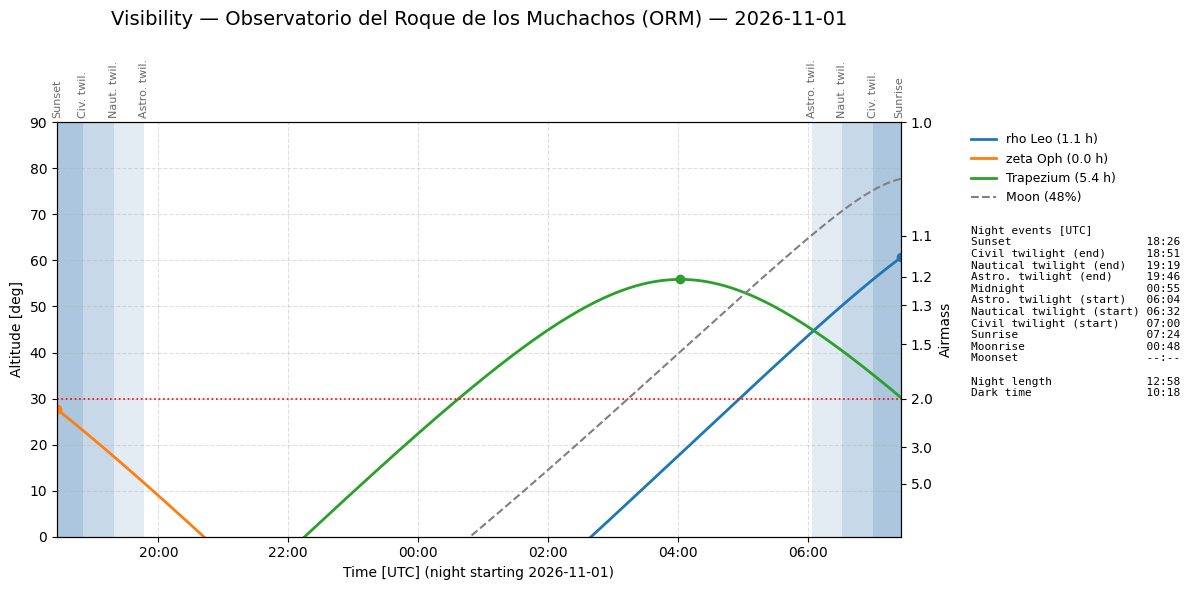


	Target     Transit (UTC)      Max alt Window (UTC)   Hours  Moon sep
	rho Leo    2026-11-02 07:26      60.6 04:57-06:04     1.12      23.8
	zeta Oph   2026-11-01 18:26      27.7 not obs.        0.00     115.8
	Trapezium  2026-11-02 04:02      55.9 00:38-06:04     5.45      56.0

	Observatory  : ORM
	Night length = 12.97 h, dark time = 10.30 h (same values as 'night_info')
	Events (UTC) : sunset 18:26, midnight 00:55, sunrise 07:24

	Figure: ['visibility_demo.pdf', 'visibility_demo.pkl'] in data_and_results/obs/results

Single target given as a coordinate dictionary (min_alt = 40 deg as a Quantity):
	Key 'Target': window 01:31-06:04 UTC, 4.56 h above 40 deg


In [9]:
vis = visibility(
                 targets=targets,
                 observatory=observatory,
                 night=night,
                 min_alt=30,
                 show=True  # Shown inline
                )
vis_files = savefig_pkl(vis['fig'], work_dir_results / "visibility_demo")

trapezium_dict = {  # Coordinate dictionary: a single target
                  'ra'  : "05:35:16.46",
                  'dec' : "-05:23:22.8",
                 }
vis_single     = visibility(
                            targets=trapezium_dict,
                            observatory=observatory,
                            night=night,
                            min_alt=40 * u.deg,  # Quantity with angular units
                            show=False
                           )
plt.close(vis_single['fig'])  # Not shown or saved: only the results are used


print(f"\n\t{'Target':<10} {'Transit (UTC)':<17} {'Max alt':>8} {'Window (UTC)':<13} {'Hours':>6} {'Moon sep':>9}")
for name, res in vis['targets'].items():
    window = f"{res['start'][-5:]}-{res['end'][-5:]}" if res['start'] is not None else "not obs."
    print(f"\t{name:<10} {res['transit']:<17} {res['max_alt']:8.1f} {window:<13} {res['hours']:6.2f} {res['moon_sep']:9.1f}")
print(f"\n\tObservatory  : {observatory}")
print(f"\tNight length = {vis['night_hours']:.2f} h, dark time = {vis['dark_hours']:.2f} h (same values as 'night_info')")
print(f"\tEvents (UTC) : sunset {vis['events']['sunset'][-5:]}, midnight {vis['events']['midnight'][-5:]}, sunrise {vis['events']['sunrise'][-5:]}")

print(f"\n\tFigure: {[p.name for p in vis_files]} in {work_dir_results}")

single = vis_single['targets']['Target']  # A single target given without a name is labeled 'Target'
print("\nSingle target given as a coordinate dictionary (min_alt = 40 deg as a Quantity):")
print(f"\tKey 'Target': window {single['start'][-5:]}-{single['end'][-5:]} UTC, {single['hours']:.2f} h above 40 deg")

## Example 8: Annual visibility of rho Leo from the ORM

Visibility of a target over a year (proposal planning).

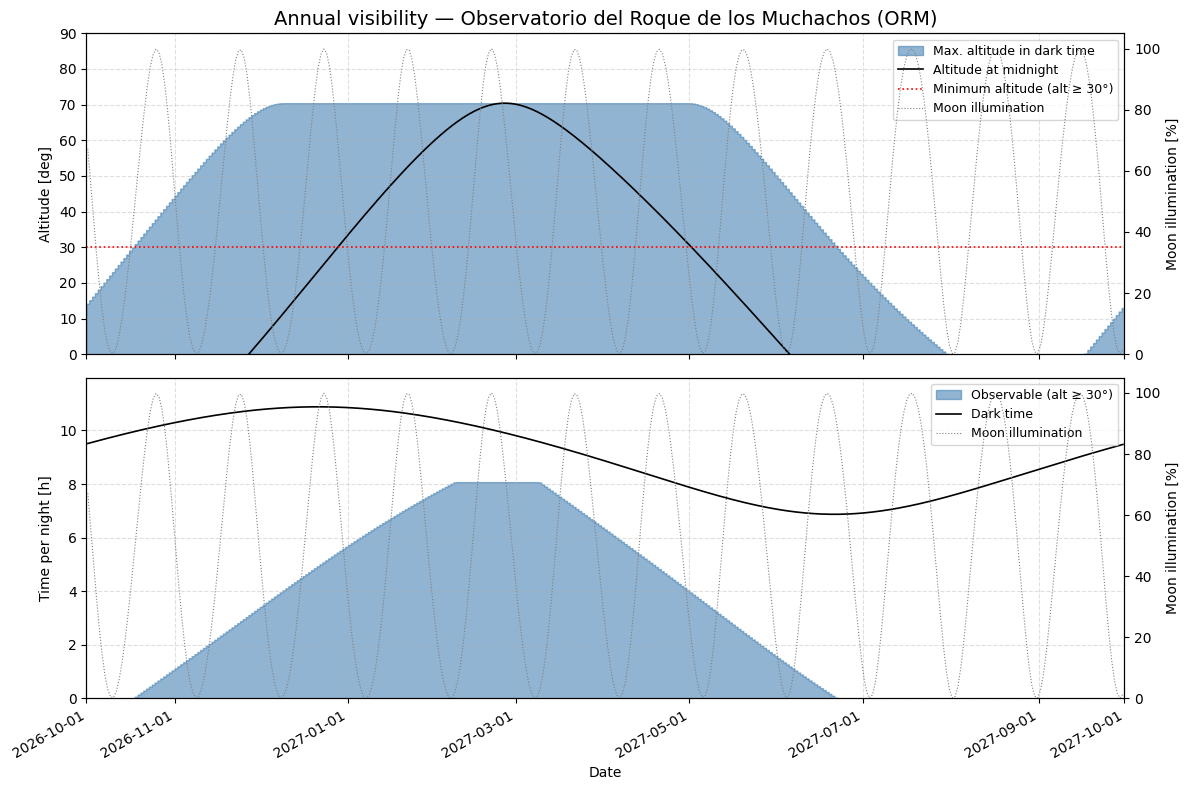


	Nights with >= 1 h observable = 220 of 365
	Best night                    = 2027-02-12 (8.07 h)
	Period plotted                = 2026-10-01 to 2027-10-01 (morning after the last night)

	Month     Observable h/night  Dark h/night  Max alt (deg)
	2026-10                 0.25          9.91           28.9
	2026-12                 4.55         10.86           70.2
	2027-02                 8.03         10.15           70.4
	2027-04                 5.18          8.38           70.4
	2027-06                 0.53          6.92           35.6
	2027-08                 0.00          8.05          -10.1

	Figure: ['annual_visibility_demo.pdf', 'annual_visibility_demo.pkl'] in data_and_results/obs/results


In [10]:
annual = annual_visibility(
                           coords=targets['rho Leo'],
                           observatory=observatory,
                           start_date="2026-10-01",
                           n_nights=365,
                           min_alt=30,
                           show=True
                          )
annual_files = savefig_pkl(annual['fig'], work_dir_results / "annual_visibility_demo")


print(f"\n\tNights with >= 1 h observable = {annual['n_observable']} of {len(annual['nights'])}")
print(f"\tBest night                    = {annual['best_night']} ({np.max(annual['hours']):.2f} h)")
print(f"\tPeriod plotted                = {annual['nights'][0]} to 2027-10-01 (morning after the last night)")
print(f"\n\t{'Month':<8} {'Observable h/night':>19} {'Dark h/night':>13} {'Max alt (deg)':>14}")
for month in ["2026-10", "2026-12", "2027-02", "2027-04", "2027-06", "2027-08"]:
    mask = np.array([n.startswith(month) for n in annual['nights']])
    print(f"\t{month:<8} {np.mean(annual['hours'][mask]):19.2f} {np.mean(annual['dark_hours'][mask]):13.2f} {np.nanmean(annual['max_alt'][mask]):14.1f}")
print(f"\n\tFigure: {[p.name for p in annual_files]} in {work_dir_results}")

## Example 9: Upcoming eclipses of the binary ASAS J052919-1617.3

Upcoming primary and secondary eclipses (HJD and JD reference epochs).

In [11]:
print(f"\nCoordinates of the binary : {binary_coords}")
print(f"Orbital period            : {binary_period:.6f} days")
print(f"Reference epoch (HJD)     : {binary_hjd0:.5f}")
print(f"Observatory               : {observatory}")

for phase, label in [(0., "Primary"), (0.5, "Secondary")]:
    events = periodic_event(
                            coords=binary_coords,
                            period=binary_period,
                            observatory=observatory,
                            hjd0=binary_hjd0,
                            start_time=night,
                            n_events=5,
                            min_alt=30,
                            phase=phase
                           )

    print(f"\n{label} eclipses (phase {phase}):")
    print(f"\t{'Cycle':>6} | {'Date & time (UTC)':^20} | {'HJD':^14} | {'Observable':^10} | {'Altitude':>8}")
    for cycle, date, hjd, obs_flag, alt in zip(events['cycles'], events['events'], events['events_hjd'], events['observable'], events['altitude']):
        print(f"\t{cycle:6d} | {date:<20} | {hjd:14.5f} | {'Yes' if obs_flag else 'No':^10} | {alt:6.1f} deg")
print("\n\t(Observable: astronomical night, Sun below -18 deg, and altitude >= 30 deg)")

events_jd = periodic_event(
                           coords=binary_coords,
                           period=binary_period,
                           observatory=observatory,
                           jd0=events['jd0'],  # Same epoch given as a JD: the ephemeris is applied in JD
                           start_time=night,
                           n_events=1
                          )
print(f"\nFirst primary eclipse with the epoch given as JD {events_jd['jd0']:.5f}: {events_jd['events'][0]} UTC")
print("\t(The ephemeris is linear in JD instead of HJD: the predicted times differ by the change of the")
print("\t heliocentric light-travel time between the reference epoch and the event, up to ±8.3 min)")


Coordinates of the binary : 05:29:19.32 -16:17:18.7
Orbital period            : 0.660851 days
Reference epoch (HJD)     : 2459929.50048
Observatory               : ORM

Primary eclipses (phase 0.0):
	 Cycle |  Date & time (UTC)   |      HJD       | Observable | Altitude
	  2143 | 2026-11-01 04:49:22  |  2461345.70424 |    Yes     |   43.4 deg
	  2144 | 2026-11-01 20:40:56  |  2461346.36509 |     No     |  -24.3 deg
	  2145 | 2026-11-02 12:32:31  |  2461347.02594 |     No     |  -42.0 deg
	  2146 | 2026-11-03 04:24:06  |  2461347.68679 |    Yes     |   44.3 deg
	  2147 | 2026-11-03 20:15:40  |  2461348.34764 |     No     |  -28.1 deg

Secondary eclipses (phase 0.5):
	 Cycle |  Date & time (UTC)   |      HJD       | Observable | Altitude
	  2143 | 2026-11-01 12:45:09  |  2461346.03466 |     No     |  -43.9 deg
	  2144 | 2026-11-02 04:36:44  |  2461346.69551 |    Yes     |   43.9 deg
	  2145 | 2026-11-02 20:28:18  |  2461347.35636 |     No     |  -26.2 deg
	  2146 | 2026-11-03 12:19:53  

## Example 10: Phases at given times of ASAS J052919-1617.3

Phases at given observation times.

In [12]:
obs_times  = ["2026-11-02T01:30:00", "2026-11-03T05:00:00", "2026-11-04T03:45:00"]
obs_phases = obs_phase(
                       coords=binary_coords,
                       period=binary_period,
                       observatory=observatory,
                       times=obs_times,
                       hjd0=binary_hjd0
                      )
obs_phases_jd = obs_phase(
                          coords=binary_coords,
                          period=binary_period,
                          observatory=observatory,
                          times=obs_times,
                          jd0=obs_phases['jd0']  # Same reference epoch, as a JD
                         )


print(f"\nReference epoch: HJD {obs_phases['hjd0']:.5f} (JD {obs_phases['jd0']:.5f})")
print(f"Observatory    : {observatory}")
print(f"\n\t{'Time (UTC)':<20} | {'JD':^14} | {'HJD':^14} | {'Phase (HJD)':^11} | {'Phase (JD)':^10}")
for t, jd, hjd, phase, phase_jd in zip(obs_phases['times'], obs_phases['times_jd'], obs_phases['times_hjd'], obs_phases['phases'], obs_phases_jd['phases']):
    print(f"\t{t:<20} | {jd:14.5f} | {hjd:14.5f} | {phase:^11.4f} | {phase_jd:^10.4f}")
print("\n\t(Use HJD for phases of binaries; the JD phases drift with the heliocentric light-travel time)")


Reference epoch: HJD 2459929.50048 (JD 2459929.49610)
Observatory    : ORM

	Time (UTC)           |       JD       |      HJD       | Phase (HJD) | Phase (JD)
	2026-11-02 01:30:00  |  2461346.56250 |  2461346.56583 |   0.3038    |   0.3054  
	2026-11-03 05:00:00  |  2461347.70833 |  2461347.71172 |   0.0377    |   0.0392  
	2026-11-04 03:45:00  |  2461348.65625 |  2461348.65968 |   0.4722    |   0.4736  

	(Use HJD for phases of binaries; the JD phases drift with the heliocentric light-travel time)


## Example 11: Phase coverage of a 6-night run of ASAS J052919-1617.3

Phase coverage of an observing run, a night with full coverage and a night without astronomical night.

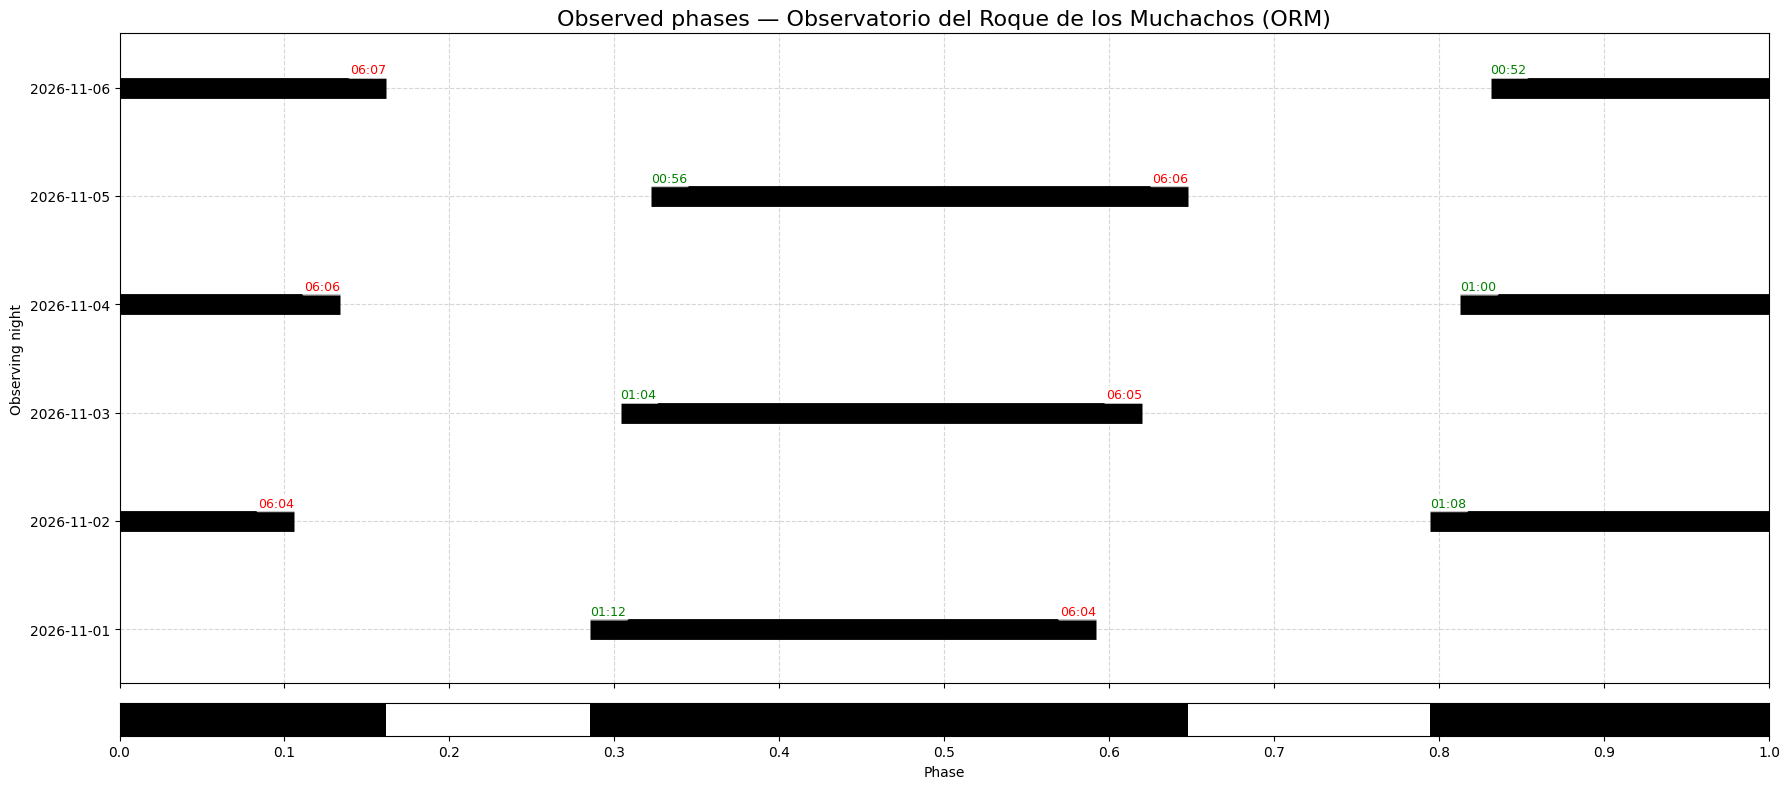


Observatory: ORM
	Night       |   Phase coverage   |               Window (UTC)               
	2026-11-01  |  0.285  ->   0.592 | 2026-11-02 01:12:36 - 2026-11-02 06:04:19
	2026-11-02  |  0.795  ->   0.106 | 2026-11-03 01:08:40 - 2026-11-03 06:04:56
	2026-11-03  |  0.304  ->   0.620 | 2026-11-04 01:04:44 - 2026-11-04 06:05:34
	2026-11-04  |  0.813  ->   0.134 | 2026-11-05 01:00:48 - 2026-11-05 06:06:12
	2026-11-05  |  0.322  ->   0.648 | 2026-11-06 00:56:52 - 2026-11-06 06:06:50
	2026-11-06  |  0.831  ->   0.162 | 2026-11-07 00:52:56 - 2026-11-07 06:07:29

	(Coverage wraps through phase 0 when start > end)
	Figure: ['phase_coverage_demo.pdf', 'phase_coverage_demo.pkl'] in data_and_results/obs/results

Period of 0.15 d on the night of 2026-11-01: full coverage = True (observable window longer than the period)

High-latitude site (60 N) on 2026-06-21: phases = [None, None]


In [13]:
nights_run = ["2026-11-01", "2026-11-02", "2026-11-03", "2026-11-04", "2026-11-05", "2026-11-06"]

coverage = obs_phase_night(
                           coords=binary_coords,
                           period=binary_period,
                           observatory=observatory,
                           nights=nights_run,
                           hjd0=binary_hjd0,
                           min_alt=30,
                           show=True
                          )
coverage_files = savefig_pkl(coverage['fig'], work_dir_results / "phase_coverage_demo")

coverage_short = obs_phase_night(
                                 coords=binary_coords,
                                 period=0.15,  # Shorter than the observable window (days)
                                 observatory=observatory,
                                 nights=night,
                                 hjd0=binary_hjd0,
                                 min_alt=30,
                                 show=False
                                )
plt.close(coverage_short['fig'])  # Not shown or saved: only the results are used

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    coverage_north = obs_phase_night(
                                     coords=binary_coords,
                                     period=binary_period,
                                     observatory=high_latitude_site,
                                     nights="2026-06-21",
                                     hjd0=binary_hjd0,
                                     show=False
                                    )
plt.close(coverage_north['fig'])


print(f"\nObservatory: {observatory}")
print(f"\t{'Night':<11} | {'Phase coverage':^18} | {'Window (UTC)':^41}")
for n, (p_min, p_max), (t_min, t_max) in zip(coverage['nights'], coverage['phases'], coverage['times']):
    if p_min is None:
        print(f"\t{n:<11} | {'not observable':^18} | {'---':^41}")
    else:
        print(f"\t{n:<11} | {p_min:6.3f}  ->  {p_max:6.3f} | {t_min} - {t_max}")
print("\n\t(Coverage wraps through phase 0 when start > end)")
print(f"\tFigure: {[p.name for p in coverage_files]} in {work_dir_results}")

print(f"\nPeriod of 0.15 d on the night of {night}: full coverage = {coverage_short['full_coverage'][0]} (observable window longer than the period)")
print(f"\n{high_latitude_site['name']} on 2026-06-21: phases = {coverage_north['phases'][0]}")
for w in caught:
    if w.category is UserWarning:  # Only the warning issued by 'obs_phase_night' (astroplan uses its own subclasses)
        print(f"\tWarning: {w.message}")

## Example 12: Telescope pointing (Trapezium, 2026-11-02 01:30 UTC)

Telescope pointing.

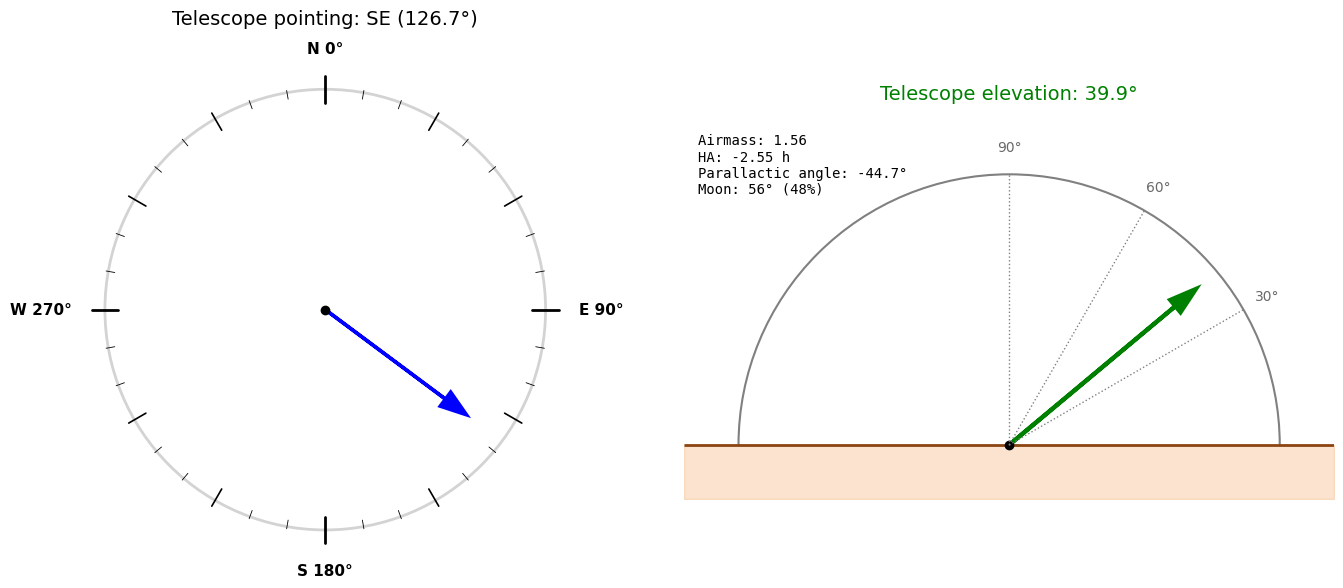


Observatory: ORM
	Azimuth           = 126.67 deg (SE)
	Elevation         = 39.86 deg
	Airmass           = 1.560
	Hour angle        = -2.55 h (LST 03:03:49; negative: East of the meridian)
	Parallactic angle = -44.7 deg
	Moon              = 56.2 deg away, 48% illuminated

	Figure: ['telescope_pointing_demo.pdf', 'telescope_pointing_demo.pkl'] in data_and_results/obs/results


In [14]:
pointing = telescope_pointing(
                              coords=targets['Trapezium'],
                              observatory=observatory,
                              obstime="2026-11-02T01:30:00",
                              show=True
                             )
pointing_files = savefig_pkl(pointing['fig'], work_dir_results / "telescope_pointing_demo")


print(f"\nObservatory: {observatory}")
print(f"\tAzimuth           = {pointing['azimuth']:.2f} deg ({pointing['direction']})")
print(f"\tElevation         = {pointing['elevation']:.2f} deg")
print(f"\tAirmass           = {pointing['airmass']:.3f}")
print(f"\tHour angle        = {pointing['hour_angle']:+.2f} h (LST {pointing['lst']}; negative: East of the meridian)")
print(f"\tParallactic angle = {pointing['parallactic_angle']:.1f} deg")
print(f"\tMoon              = {pointing['moon_sep']:.1f} deg away, {pointing['moon_illumination']:.0f}% illuminated")
print(f"\n\tFigure: {[p.name for p in pointing_files]} in {work_dir_results}")

## Example 13: BinarAlt

BinarAlt observation-planning interface (launched only if RUN_BINARALT is True).

In [15]:
print("\nInput check:")
try:
    binaralt(block="yes")
except TypeError as e:  # 'block' must be a boolean
    print(f"\tRejected: {e}")

if RUN_BINARALT:
    print("\nLaunching BinarAlt in the default web browser (the server stops when the kernel is restarted or shut down)...")
    print("\tSee the user guide (READMEs/BinarAlt_UserGuide.pdf, also opened from the question-mark icon of the interface).")
    print(f"\tExample target list for 'Import CSV': {work_dir_data / 'northcircumpolar_targets.csv'}\n")
    binaralt(block=False)  # Background server: the notebook stays usable and the server stops with the kernel
else:
    print("\n\tSkipped: set RUN_BINARALT = True in SETUP to launch the interface (it opens a browser tab).")
    print(f"\tExample target list for its 'Import CSV' button: {work_dir_data / 'northcircumpolar_targets.csv'}")


Input check:
	Rejected: Blocking-mode flag 'block' must be a boolean. Got str.

	Skipped: set RUN_BINARALT = True in SETUP to launch the interface (it opens a browser tab).
	Example target list for its 'Import CSV' button: data_and_results/obs/data/northcircumpolar_targets.csv
